In [1]:
!pip install -q pyLDAvis gensim wordcloud nltk

In [2]:
!git clone -q https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing.git health_data

In [3]:
import os, re, glob, json, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from collections import Counter
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import gensim
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

In [4]:
df = pd.read_csv("health_data/Health_Related_Headlines_Dataset.csv", encoding="latin-1")
print(df.shape)
print(df["Category"].value_counts())
df["text"] = df["Headlines"].fillna("") + " " + df["Teaser"].fillna("")
df = df.drop_duplicates("text").reset_index(drop=True)
print(df.shape)
df.head(10)

(39405, 5)
Category
Clinical Trial                   9331
Pain Management                  9195
Substance Abuse and Addiction    6775
Patient Safety                   5911
Adverse Drug Event               4118
Immunization                     2729
Antibiotic Resistance            1346
Name: count, dtype: int64
(31720, 6)


,Date,Source,Headlines,Teaser,Category,text
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization,Special Report: Adult Vaccines -- New ACIP Rec...
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction,Combined Internet and Telephone Intervention M...
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction,Link Between Parental Alcoholism and Childhood...
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction,Methadone Dose in the Treatment of Opiate Depe...
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management,Magnet Treatment Had No Beneficial Effect on P...
5,"May, 2000",Medscape Oncology,Ask the Experts - Investigational Agents for M...,Update of important ongoing and completed clin...,Clinical Trial,Ask the Experts - Investigational Agents for M...
6,"June, 2000",Medscape Medical News,Estrogen Replacement May Negate the Benefits o...,"In a preliminary study, researchers have found...",Adverse Drug Event,Estrogen Replacement May Negate the Benefits o...
7,"August, 2000",Medscape Pharmacotherapy,MEDLINE Abstracts: Thalidomide Clinical Trials,A regularly updated reference resource summari...,Clinical Trial,MEDLINE Abstracts: Thalidomide Clinical Trials...
8,"January, 2001",The AIDS ReaderÂ®,IRB/FDA Requirements Relevant to HIV/AIDS Clin...,"During the past few years, a number of abuses ...",Clinical Trial,IRB/FDA Requirements Relevant to HIV/AIDS Clin...
9,"January, 2001",The AIDS ReaderÂ®,HIV Clinical Trials in Correctional Settings: ...,Explore the advancements in clinical trial met...,Clinical Trial,HIV Clinical Trials in Correctional Settings: ...


In [5]:
stop_words = set(stopwords.words("english"))
stop_words |= {"rt", "via", "amp", "new", "say", "says", "said", "u", "one", "get", "could", "may", "also", "would", "health", "news"}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+|#", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return [t for t in tokens if t not in stop_words]

df["tokens"] = df["text"].apply(clean_text)
df["clean_text"] = df["tokens"].apply(" ".join)
df = df[df["tokens"].str.len() > 0].reset_index(drop=True)
print(df.shape)

(31720, 8)


In [6]:
pd.set_option("display.max_colwidth", 120)
df[["text", "clean_text"]].sample(10, random_state=42)

,text,clean_text
23797,Reducing Pediatric Distress During Vaccination What strategies may help children cope with the pain and anxiety of v...,reducing pediatric distress vaccination strategy help child cope pain anxiety vaccine administration find work doesnt
24584,Perioperative Ventilation in Obese Versus Non-obese Patients How does postop respiratory status vary among obese and...,perioperative ventilation obese versus nonobese patient postop respiratory status vary among obese nonobese patient ...
13845,Small Intestinal GIST in a Young Adult Woman While gastrointestinal stromal tumor is the most common sarcoma of the ...,small intestinal gist young adult woman gastrointestinal stromal tumor common sarcoma tract unusual young adult pres...
30311,FDA Panel Nixes Novel Alzheimer's Therapy An FDA advisory panel questions the evidence showing beneficial effects of...,fda panel nix novel alzheimers therapy fda advisory panel question evidence showing beneficial effect therapy combin...
4706,ABCB1 Polymorphisms in Fluoropyrimidine-Treated Patients Can genotyping reduce ADRs associated with fluorouracil?,abcb polymorphism fluoropyrimidinetreated patient genotyping reduce adrs associated fluorouracil
11256,Contraindications to Oral Anticoagulation in Atrial Fibrillation What factors are associated with oral anticoagulant...,contraindication oral anticoagulation atrial fibrillation factor associated oral anticoagulant contraindication infl...
25968,New Alcohol Use Disorder Guideline Emphasizes Medication A new practice guideline offers evidence-based recommendati...,alcohol use disorder guideline emphasizes medication practice guideline offer evidencebased recommendation treatment...
1530,1 Billion Tobacco Deaths This Century? A massive death toll from tobacco-related caused may be possible unless urgen...,billion tobacco death century massive death toll tobaccorelated caused possible unless urgent action taken agency warns
11932,Chronic CKD-MBDs: What the Endocrinologist Needs to Know How should skeletal and metabolic disorders be managed in p...,chronic ckdmbds endocrinologist need know skeletal metabolic disorder managed patient ckdmbds
11031,Coronary Artery Occlusions Diagnosed by Transthoracic Doppler This study assessed the feasibility and accuracy of di...,coronary artery occlusion diagnosed transthoracic doppler study assessed feasibility accuracy diagnosing occlusion t...


In [7]:
all_tokens = [t for toks in df["tokens"] for t in toks]
freq = Counter(all_tokens)
print("Total tokens:", len(all_tokens), "| Vocabulary size:", len(freq))
freq_df = pd.DataFrame(freq.most_common(), columns=["word", "count"])
freq_df.head(20)

Total tokens: 598827 | Vocabulary size: 29756


,word,count
0,patient,10185
1,risk,5851
2,study,5665
3,drug,4619
4,cancer,4609
5,pain,4560
6,treatment,4382
7,use,3796
8,disease,3281
9,therapy,2760


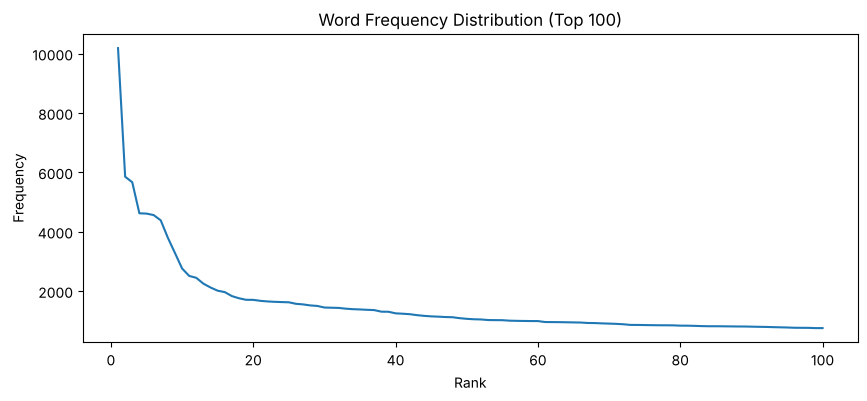

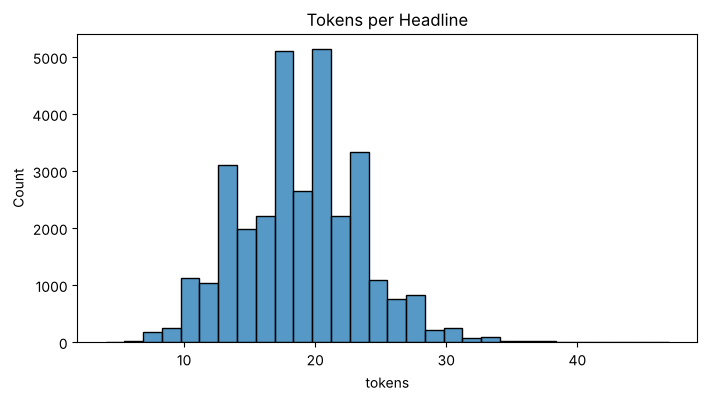

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(range(1, 101), freq_df["count"][:100])
plt.title("Word Frequency Distribution (Top 100)")
plt.xlabel("Rank"); plt.ylabel("Frequency")
plt.show()
lengths = df["tokens"].str.len()
plt.figure(figsize=(8, 4))
sns.histplot(lengths, bins=30)
plt.title("Tokens per Headline")
plt.show()

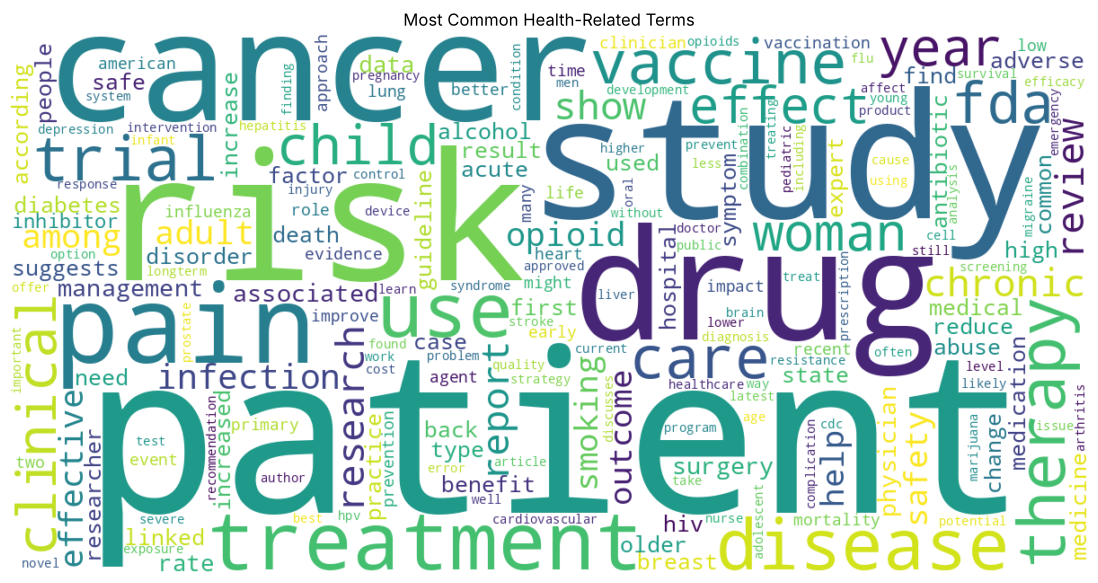

In [9]:
wc = WordCloud(width=1200, height=600, background_color="white", max_words=200, colormap="viridis").generate_from_frequencies(freq)
plt.figure(figsize=(15, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Health-Related Terms")
plt.show()

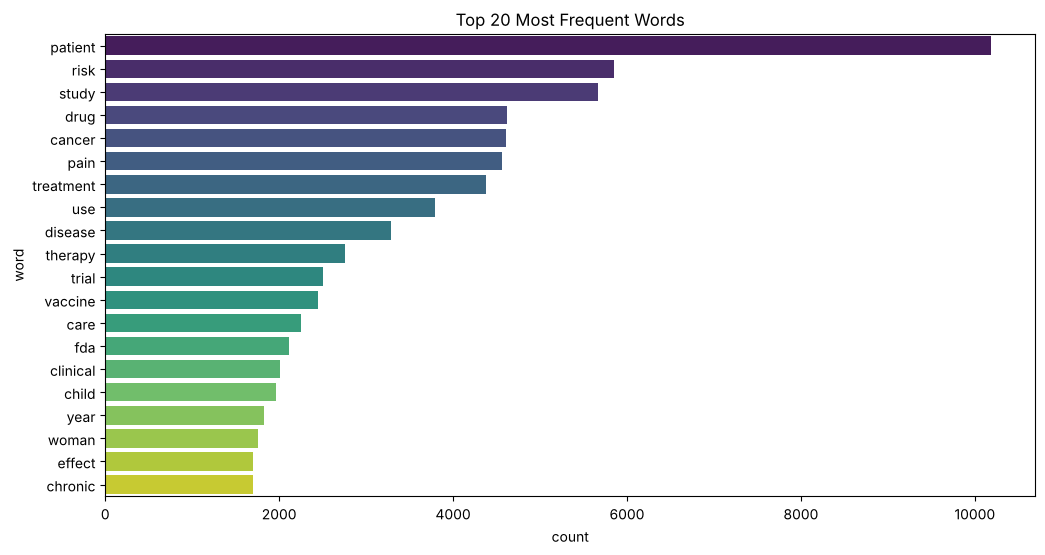

In [10]:
top20 = freq_df.head(20)
plt.figure(figsize=(12, 6))
sns.barplot(x="count", y="word", data=top20, palette="viridis", hue="word", legend=False)
plt.title("Top 20 Most Frequent Words")
plt.show()

In [11]:
texts = df["tokens"].tolist()
bigram = gensim.models.Phrases(texts, min_count=5, threshold=50)
bigram_mod = gensim.models.phrases.Phraser(bigram)
texts = [bigram_mod[t] for t in texts]
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=5, no_above=0.5)
corpus = [dictionary.doc2bow(t) for t in texts]
print("Dictionary size:", len(dictionary), "| Documents:", len(corpus))

Dictionary size: 10253 | Documents: 31720


4 0.3304


6 0.373


8 0.3665


10 0.3936


12 0.3897


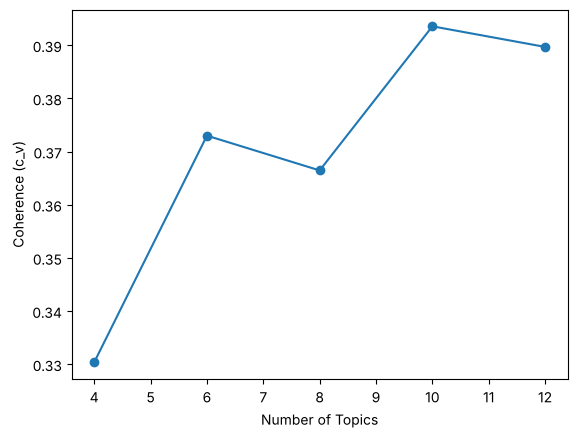

Best number of topics: 10


In [12]:
coherence = []
k_range = range(4, 13, 2)
for k in k_range:
    m = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k, random_state=42, passes=5, alpha="auto", eta="auto")
    c = CoherenceModel(model=m, texts=texts, dictionary=dictionary, coherence="c_v").get_coherence()
    coherence.append(c)
    print(k, round(c, 4))
plt.plot(list(k_range), coherence, marker="o")
plt.xlabel("Number of Topics"); plt.ylabel("Coherence (c_v)")
plt.show()
best_k = list(k_range)[int(np.argmax(coherence))]
print("Best number of topics:", best_k)

In [13]:
lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=best_k, random_state=42, passes=15, alpha="auto", eta="auto")
for i in range(best_k):
    words = [w for w, _ in lda.show_topic(i, topn=5)]
    print(f"Topic {i + 1}: {', '.join(words)}")

Topic 1: cancer, disease, hospital, prevention, prevent
Topic 2: use, child, among, study, woman
Topic 3: chemotherapy, virus, eye, crohn_disease, see
Topic 4: device, make, system, medicine, healthcare
Topic 5: vaccine, infection, antibiotic, cdc, type_diabetes
Topic 6: risk, associated, factor, study, increase
Topic 7: opioid, drug, physician, medical, case
Topic 8: research, review, clinical, guideline, expert
Topic 9: drug, therapy, treatment, trial, data
Topic 10: patient, pain, treatment, study, outcome


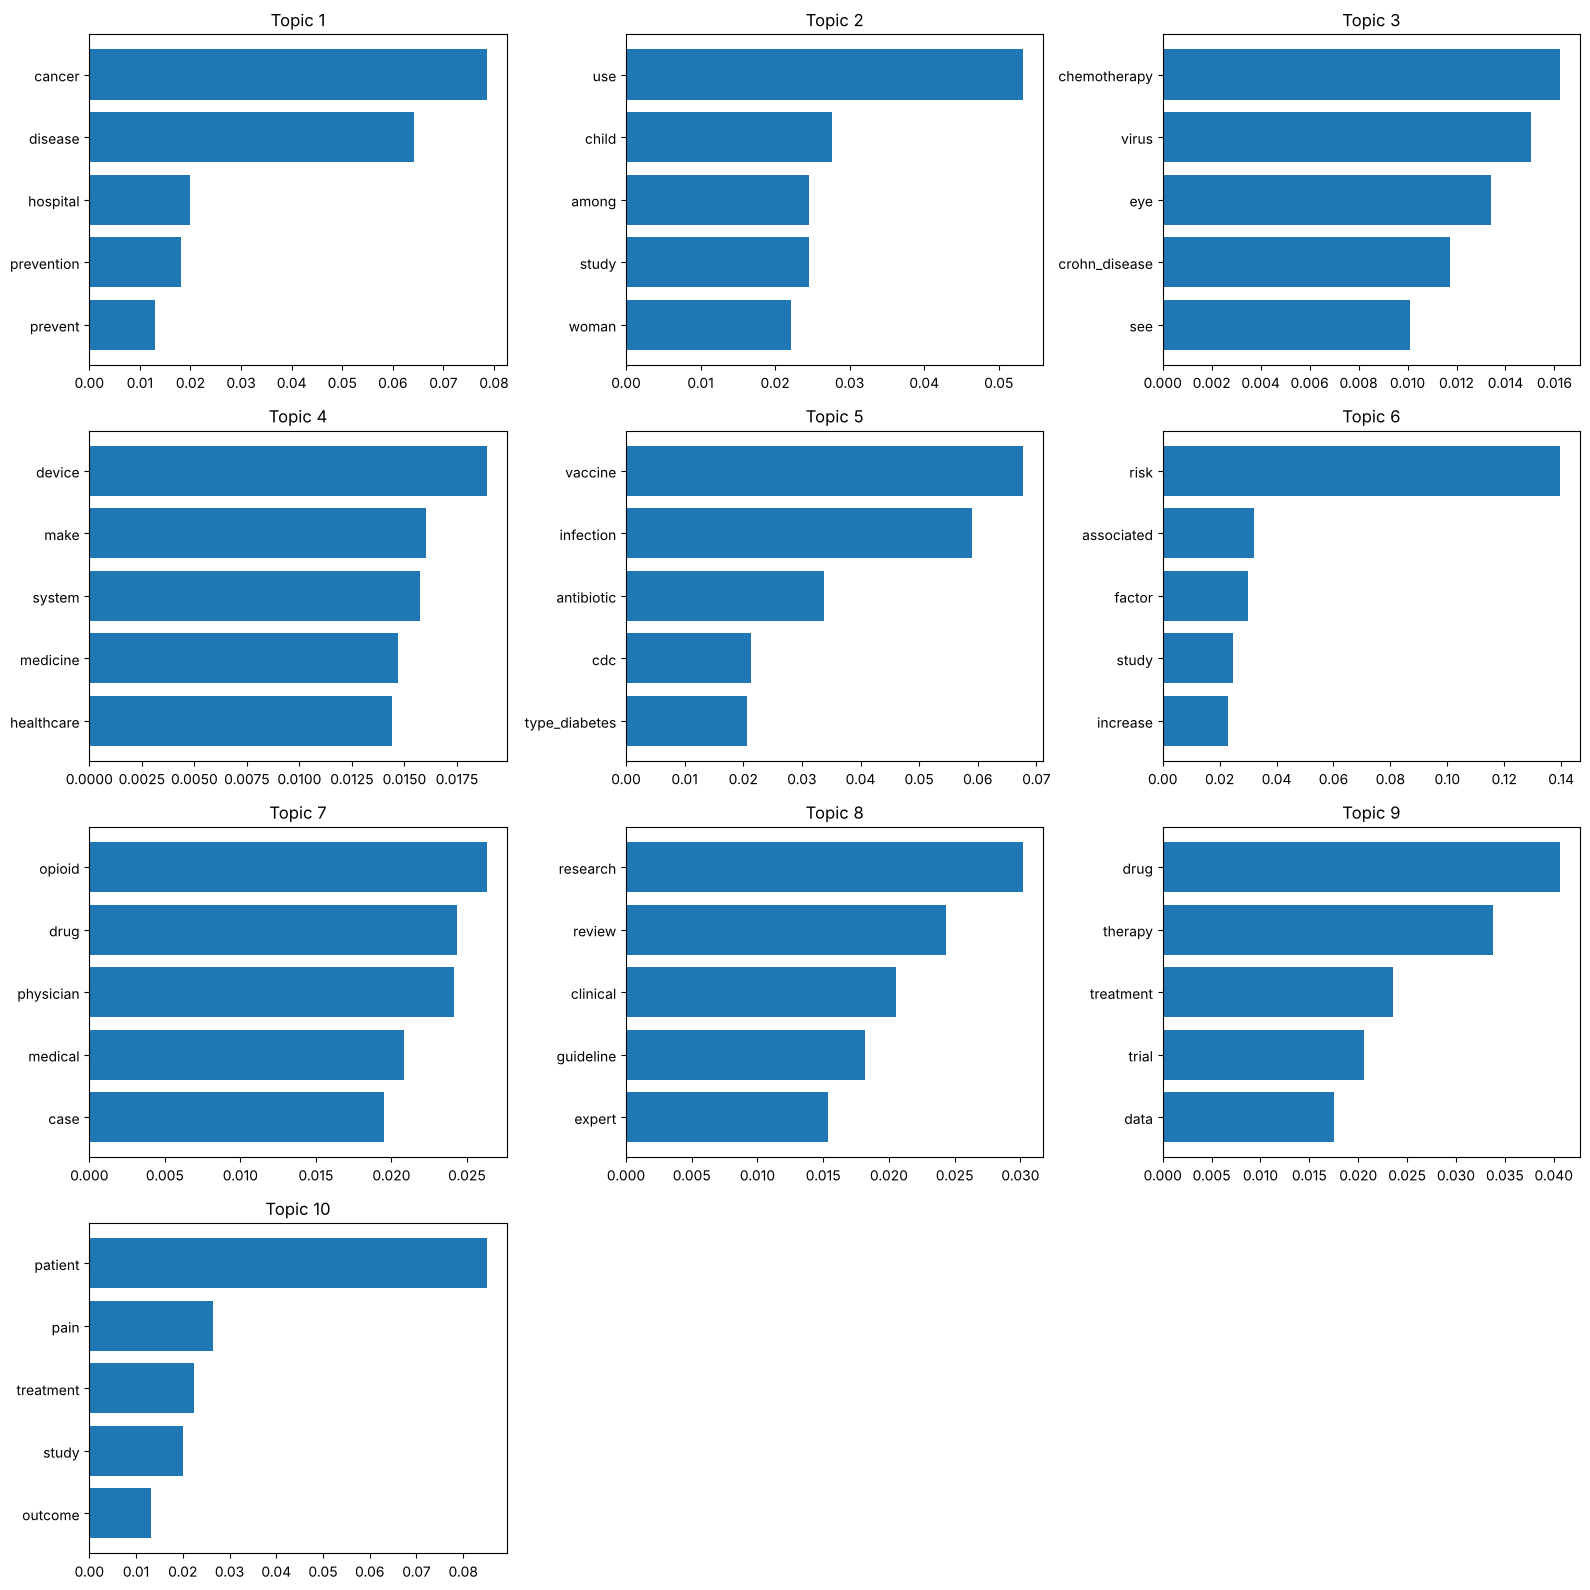

In [14]:
fig, axes = plt.subplots(int(np.ceil(best_k / 3)), 3, figsize=(16, 4 * int(np.ceil(best_k / 3))))
for i, ax in enumerate(axes.ravel()):
    if i >= best_k:
        ax.axis("off")
        continue
    tw = lda.show_topic(i, topn=5)
    ax.barh([w for w, _ in tw][::-1], [p for _, p in tw][::-1])
    ax.set_title(f"Topic {i + 1}")
plt.tight_layout()
plt.show()

In [15]:
df["dominant_topic"] = [max(lda.get_document_topics(b), key=lambda x: x[1])[0] + 1 if b else 0 for b in corpus]
print(df["dominant_topic"].value_counts().sort_index())
df[["text", "dominant_topic"]].sample(10, random_state=1)

dominant_topic
1       824
2      3726
3       120
4       479
5       807
6      1554
7      2547
8      2526
9      4821
10    14316
Name: count, dtype: int64


,text,dominant_topic
23291,A Decision Wheel to Reduce Restraint Use in a Med-Surg ICU This article describes a decision support tool that may h...,10
14802,Superior vs Inferior Glaucoma Drainage Device Implantation How do these two locations for device implantation placem...,10
13345,"Advanced Lung Cancer Missed in Primary Care An analysis of more than 20,000 lung cancer cases in the United Kingdom...",10
26742,Mediterranean Diet and IVF Success Rate Should women undergoing IVF increase their intake of olive oil and whole gra...,8
17019,Smoking a Cause of Psychosis? A meta-analysis shows high rates of smoking at first onset of psychosis and earlier on...,2
9068,Does Smoking Affect Surgical Outcomes? Commentary on a study on the effect of smoking on outcomes after colorectal s...,10
4906,Frequent Cocaine Use Linked to Alterations in DNA Frequent cocaine use triggers long-lasting changes to genes expres...,2
17872,Prevalence of Cirrhosis in Hepatitis C Patients How likely are patients with chronic hepatitis C to present with cir...,10
22718,Low-Dose Ropivacaine for Interscalene Brachial Plexus Block This study examined the efficacy of various dosages of r...,10
11813,Effect of Lifetime Alcohol Consumption on Severity of NAFLD Does lifetime alcohol consumption predispose a patient t...,10


In [16]:
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda, corpus, dictionary, mds="mmds")
pyLDAvis.save_html(vis, "lda_visualization.html")
vis

/usr/local/lib/python3.13/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
9      0.009146  0.022313       1        1  23.498225
8      0.049752 -0.379769       2        1  14.047974
1     -0.363148 -0.127729       3        1  12.754610
7     -0.215222  0.391467       4        1  11.106607
6      0.311427 -0.315391       5        1  10.103758
0      0.435017 -0.030799       6        1   7.875765
5      0.085757  0.411571       7        1   7.849366
3     -0.244866 -0.396822       8        1   5.267594
4     -0.423167  0.153802       9        1   4.461562
2      0.355303  0.271356      10        1   3.034539, topic_info=              Term          Freq         Total Category  logprob  loglift
67         patient  10306.000000  10306.000000  Default  30.0000  30.0000
594           risk   5618.000000   5618.000000  Default  29.0000  29.0000
176         cancer   3171.000000   3171.000000  Default  28.0000  28.0000
202            use   3494.000000   3494.000000  Default  27.0000  27.0000
248        disease   2587.000000   2587.000000  Default  26.0000  26.0000
...            ...           ...           ...      ...      ...      ...
9315   transgender     82.104212     82.966986  Topic10  -5.2439   3.4847
2775       culture     82.054562     82.917307  Topic10  -5.2445   3.4847
3239        versus     76.316817     77.179616  Topic10  -5.3170   3.4839
5085  laparoscopic     74.314545     75.177259  Topic10  -5.3436   3.4836
1653         laser     73.931465     74.794223  Topic10  -5.3488   3.4835

[434 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
34        3  0.524831      abuse
34        5  0.473302      abuse
145       5  0.996619     access
49        1  0.056993  according
49        2  0.281653  according
...     ...       ...        ...
119       5  0.012266       year
119       6  0.005520       year
119       8  0.001840       year
119       9  0.001840       year
1288      3  0.997205      young

[541 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[10, 9, 2, 8, 7, 1, 6, 4, 5, 3])